# Northwind Margin Leakage & Discount Elasticity Audit

**Objective:** Evaluate whether historical price discounting across Northwind's product catalog drives statistically significant increases in order volume (`Quantity`), or if discounting erodes net margin without generating incremental unit demand.

### Pipeline Architecture
1. **Data Extraction:** Query line-item transactions (`619,989` rows) from `northwind.db` joining `"Order Details"`, `Products`, and `Categories`.
2. **Non-Parametric Hypothesis Testing:** Because order quantities are right-skewed and non-normal, apply a one-sided **Mann-Whitney U test** ($H_1: \text{Quantity}_{\text{Discounted}} > \text{Quantity}_{\text{Full Price}}$) per category.
3. **Decision Rule:** Flag a category as **Volume Justified** only if $p < 0.05$ *and* mean volume lift is $\ge 15\%$; otherwise flag as **Margin Leakage**.
4. **Database Write-Back:** Persist aggregated audit tables (`py_category_margin_audit` and `py_discount_tier_summary`) back to `northwind.db` for Power BI What-If simulation.

In [5]:
import sqlite3
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
print("success!")

success!


### 1. Data Extraction & Discount Distribution Inspection
We connect to `northwind.db` and join `"Order Details"`, `Products`, and `Categories` to compute line-item `NetRevenue` and `DiscountLeakage`. Before running statistical tests, we inspect the distribution of `Discount` rates to verify decimal formatting and check how frequently discounts are granted across the `619,989` line items.

In [7]:
# Connting to the database inside data/
DB_PATH = "../data/northwind.db"
conn = sqlite3.connect(DB_PATH)

query = """
SELECT
    cat.CategoryName, 
    p.ProductName, 
    od.UnitPrice, 
    od.Quantity, 
    od.Discount, 
    ROUND(od.UnitPrice * od.Quantity * (1 - od.Discount), 2) AS NetRevenue, 
    ROUND(od.UnitPrice * od.Quantity * od.Discount, 2) AS DiscountLeakage
FROM "Order Details" as od
JOIN Products p ON od.ProductID = p.ProductID
JOIN Categories cat ON p.CategoryID = cat.CategoryID
"""

df = pd.read_sql_query(query, conn)

print(f"Total line items loaded: {len(df):,}")
print("\nUnique discount value and counts:")
print(df["Discount"].value_counts().sort_index())

Total line items loaded: 619,989

Unique discount value and counts:
Discount
0.00    619151
0.01         1
0.02         2
0.03         3
0.04         1
0.05       185
0.06         1
0.10       173
0.15       157
0.20       161
0.25       154
Name: count, dtype: int64


### 2. Category-Level Mann-Whitney U Hypothesis Testing
Because B2B order quantities are non-normal and right-skewed, we use a one-sided **Mann-Whitney U test** per category ($H_0$: discounted order quantities are less than or equal to full-price quantities; $H_1$: discounted order quantities are strictly greater). Categories must pass both statistical significance ($p < 0.05$) and practical significance ($\ge 15\%$ mean lift) to be classified as **Volume Justified**.

In [9]:
df_clean = df[df["Discount"].between(0, 1)].copy()
df_clean["IsDiscounted"] = np.where(df_clean["Discount"] > 0, "Discounted", "Full Price")

results = []
for category, group in df_clean.groupby("CategoryName"):
    full_price = group[group["Discount"] == 0]["Quantity"]
    discounted = group[group["Discount"] > 0]["Quantity"]

    # One-sided Mann-Whitney U test: is discounted quantity > full-price quantity? 
    stat, p_val = stats.mannwhitneyu(discounted, full_price, alternative="greater")

    mean_full = full_price.mean()
    mean_disc = discounted.mean()
    median_full = full_price.median()
    median_disc = discounted.median()
    lift_pct = ((mean_disc - mean_full) / mean_full) * 100

    total_net_rev = group["NetRevenue"].sum()
    total_leakage = group["DiscountLeakage"].sum()

    # Verdict: p < 0.05 AND at least 15% mean volume left
    verdict = "Volume Justified" if (p_val < 0.05 and lift_pct >= 15.0) else "Margin Leakage"

    results.append({
        "CategoryName": category, 
        "OrderLines": len(group), 
        "DiscountedPct": round((len(discounted) / len(group)) * 100, 1), 
        "MedianQty_Full": median_full, 
        "MedianQty_Disc": median_disc, 
        "MeanQty_Full": round(mean_full, 2),
        "MeanQty_Disc": round(mean_disc, 2),
        "VolumeLiftPct": round(lift_pct, 2),
        "PValue": round(p_val, 4),
        "TotalNetRevenue": round(total_net_rev, 2),
        "TotalDiscountLeakage": round(total_leakage, 2),
        "AuditVerdict": verdict
    })
audit_df = pd.DataFrame(results).sort_values("TotalDiscountLeakage", ascending=False)
audit_df

,CategoryName,OrderLines,DiscountedPct,MedianQty_Full,MedianQty_Disc,MeanQty_Full,MeanQty_Disc,VolumeLiftPct,PValue,TotalNetRevenue,TotalDiscountLeakage,AuditVerdict
0,Beverages,96717,0.2,26.0,20.5,25.51,27.95,9.58,0.6056,93659372.70,18658.79,Margin Leakage
3,Dairy Products,80635,0.2,25.0,24.0,25.42,29.46,15.93,0.0739,59011077.82,16823.25,Margin Leakage
5,Meat/Poultry,48525,0.2,26.0,20.5,25.53,28.80,12.80,0.6215,66960882.09,15166.45,Margin Leakage
7,Seafood,96250,0.1,25.0,21.0,25.49,26.04,2.17,0.8789,50619288.41,10361.39,Margin Leakage
2,Confections,104642,0.1,25.0,21.0,25.42,24.54,-3.47,0.9231,66941793.86,9741.92,Margin Leakage
1,Condiments,96469,0.1,25.0,20.0,25.46,29.47,15.74,0.5343,56620856.91,7647.68,Margin Leakage
6,Produce,40302,0.1,26.0,20.0,25.59,24.07,-5.93,0.9575,33321392.07,5284.03,Margin Leakage
4,Grains/Cereals,56449,0.1,26.0,20.0,25.57,24.40,-4.58,0.9417,29215454.34,4982.22,Margin Leakage


### Key Findings: Statistical Hypothesis Test Results

* **Universal Margin Leakage ($8/8$ Categories):** None of Northwind's eight product categories achieved a statistically significant volume lift at the $\alpha = 0.05$ threshold ($p$-values range from `0.0739` in *Dairy Products* to `0.9575` in *Produce*).
* **Median Order Size Declines Under Discounting:** While isolated bulk outliers pull the *mean* quantity slightly upward in categories like *Beverages* (`25.51` $\rightarrow$ `27.95`) and *Dairy Products* (`25.42` $\rightarrow$ `29.46`), the **median order quantity drops across every single category** when discounts are applied (e.g., *Beverages* drops from `26.0` to `20.5` units).
* **Total Margin Erosion:** Across `838` discounted line items (concentrated in `5%` to `25%` discount tiers), Northwind absorbed **$88,665.73** in direct discount leakage—led by *Beverages* (`$18,658.79`), *Dairy Products* (`$16,823.25`), and *Meat/Poultry* (`$15,166.45`)—with zero statistically verifiable return in order volume.

---

### Visual Distribution & Tier Analysis
Next, we inspect the interquartile distributions across categories and evaluate whether deeper discount tiers (`15%–25%`) trigger bulk purchasing compared to shallow tiers (`5%–10%`).

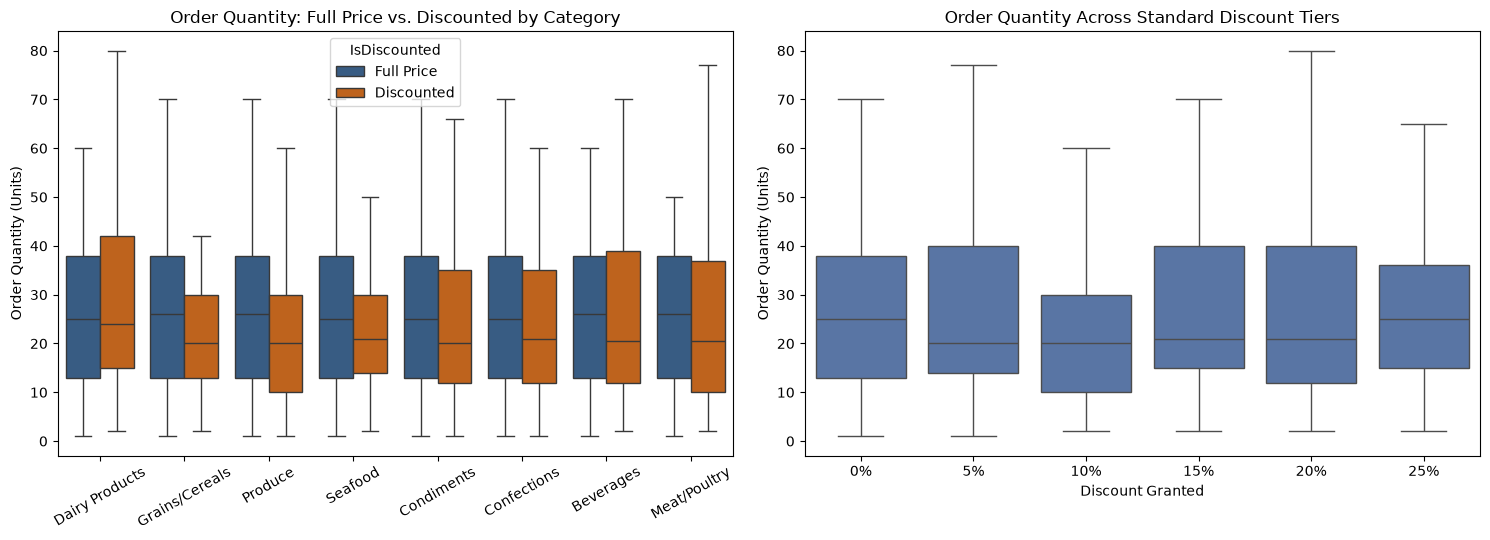

In [11]:
fit, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left Plot: Order Quantity by Category (Full Price vs. Discounted)
sns.boxplot(
    data=df_clean, 
    x="CategoryName", 
    y="Quantity", 
    hue="IsDiscounted", 
    palette={"Full Price": "#2b5c8f", "Discounted": "#d95f02"},
    showfliers=False, 
    ax=axes[0]
)
axes[0].set_title("Order Quantity: Full Price vs. Discounted by Category", fontsize=12)
axes[0].set_xlabel("")
axes[0].set_ylabel("Order Quantity (Units)")
axes[0].tick_params(axis="x", rotation=30)

# Right Plot: Order Quantity across Standard Discount Tiers
standard_tiers = df_clean[df_clean["Discount"].isin([0.0, 0.05, 0.10, 0.15, 0.20, 0.25])].copy()
standard_tiers["DiscountLabel"] = (standard_tiers["Discount"] * 100).astype(int).astype(str) + "%"

sns.boxplot(
    data=standard_tiers,
    x="DiscountLabel",
    y="Quantity",
    order=["0%", "5%", "10%", "15%", "20%", "25%"],
    color="#4c72b0",
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Order Quantity Across Standard Discount Tiers", fontsize=12)
axes[1].set_xlabel("Discount Granted")
axes[1].set_ylabel("Order Quantity (Units)")

plt.tight_layout()
plt.show()

### 3. Tier Analysis Takeaways & Database Write-Back
* **Flat Response Across All Discount Tiers:** As shown in the right-hand boxplot above, escalating discounts from `5%` up to `25%` produces no upward shift in median order size—confirming that aggressive discounting (`20%–25%`) sacrifices margin with zero volume return.
* **Persist Analytical Tables:** We now write `py_category_margin_audit` and `py_discount_tier_summary` back to `northwind.db` to power the Power BI What-If Margin Recovery Simulator.

In [12]:
# Create a clean discount-tier summary table for visualization
tier_summary = (
    standard_tiers.groupby("Discount", as_index=False)
    .agg(
        OrderLines=("Quantity", "count"),
        MedianQuantity=("Quantity", "median"),
        MeanQuantity=("Quantity", "mean"),
        TotalNetRevenue=("NetRevenue", "sum"),
        TotalDiscountLeakage=("DiscountLeakage", "sum")
    )
)
tier_summary["MeanQuantity"] = tier_summary["MeanQuantity"].round(2)
tier_summary["TotalNetRevenue"] = tier_summary["TotalNetRevenue"].round(2)
tier_summary["TotalDiscountLeakage"] = tier_summary["TotalDiscountLeakage"].round(2)

# Write both Python-computed tables to SQLite
audit_df.to_sql("py_category_margin_audit", conn, if_exists="replace", index=False)
tier_summary.to_sql("py_discount_tier_summary", conn, if_exists="replace", index=False)

conn.close()
print("Saved 'py_category_margin_audit' and 'py_discount_tier_summary' to northwind.db!")

Saved 'py_category_margin_audit' and 'py_discount_tier_summary' to northwind.db!
